In [5]:
from pipeline import PipelineEDA

## 1. Cargar

In [12]:
pipeline = PipelineEDA("data/online_retail.csv")
pipeline.df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Análisis inicial

In [13]:
pipeline.analizar()

ARCHIVO: online_retail.csv

INFORMACION GENERAL DEL DATASET:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303
min    -80995.000000  -11062.060000   12346.000000
25%         1.000000       1.250000   13953.000000
50%         3.000000       2.080000   15152

## 3. Nulos

In [14]:
pipeline.tratar_nulos(["CustomerID"])

Se eliminaron los nulos de: CustomerID


In [15]:
pipeline.ver_nulos()


ANALISIS DE VALORES NULOS

TABLA DE VALORES NULOS:
             Cantidad de nulos  Porcentaje de nulos
InvoiceNo                    0                  0.0
StockCode                    0                  0.0
Description                  0                  0.0
Quantity                     0                  0.0
InvoiceDate                  0                  0.0
UnitPrice                    0                  0.0
CustomerID                   0                  0.0
Country                      0                  0.0

TOTAL DE VALORES NULOS:
0


## 4. Duplicados

In [16]:
pipeline.ver_duplicados()

Filas duplicadas: 5,225


In [17]:
pipeline.eliminar_duplicados()

Filas eliminadas: 5,225
Filas restantes: 401,604


## 5. Facturas canceladas

In [18]:
pipeline.filtrar_facturas_canceladas(obtener=True).head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [20]:
pipeline.filtrar_facturas_canceladas()


Se eliminaron las facturas canceladas.


## 6. Cantidades y precios inválidos

In [21]:
pipeline.filtrar_ventas_positivas()

Filas eliminadas: 40
Filas restantes: 392,692


## 7. Códigos que no son productos

In [22]:
no_productos = ["POST", "DOT", "M", "D", "C2", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS"]

In [23]:
pipeline.filtrar_codigos_no_producto(no_productos, obtener=True)['Description'].value_counts()

Description
POSTAGE                       1099
Manual                         279
CARRIAGE                       133
DOTCOM POSTAGE                  16
Bank Charges                    12
PADS TO MATCH ALL CUSHIONS       3
Name: count, dtype: int64

In [24]:
pipeline.filtrar_codigos_no_producto(no_productos)

Filas eliminadas: 1,542
Filas restantes: 391,150


## 8. Descripciones

In [25]:
pipeline.limpiar_descripciones()

Filas corregidas: 94,033


## 9. Tipos de datos

In [26]:
pipeline.convertir_tipos(columnas_int=["CustomerID"], columnas_fecha=["InvoiceDate"])

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                   str
dtype: object


## 10. Outliers

In [27]:
pipeline.df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,391150.000000,391150.000000
mean,13.145300,2.874372
std,180.807831,4.284738
min,1.000000,0.040000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,649.500000


In [28]:
pipeline.eliminar_outliers(["Quantity", "UnitPrice"])

Quantity: limite = 120.00
UnitPrice: limite = 12.75
Filas eliminadas: 7,384
Filas restantes: 383,766


In [29]:
pipeline.df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,383766.000000,383766.000000
mean,10.030761,2.696806
std,14.657576,2.464347
min,1.000000,0.040000
25%,2.000000,1.250000
50%,6.000000,1.850000
75%,12.000000,3.750000
max,120.000000,12.750000


## 11. Columnas nuevas

In [30]:
pipeline.crear_columnas()

Columnas nuevas: Total, Mes, Dia, Hora


In [31]:
pipeline.df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Total,Mes,Dia,Hora
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


## 12. Resultado

In [32]:
pipeline.resumen_limpieza()

RESUMEN DE LIMPIEZA
Filas iniciales: 541,909
Filas finales: 383,766
Eliminadas: 158,143 (29.2%)
Nulos restantes: 0
Duplicados restantes: 0


In [33]:
pipeline.guardar("online_retail_limpio.csv")

Guardado en: online_retail_limpio.csv


### EDA

RESUMEN GENERAL
Facturas : 17,951
Clientes : 4,289
Productos: 3,610
Países   : 37
Ventas   : 6,846,370.96


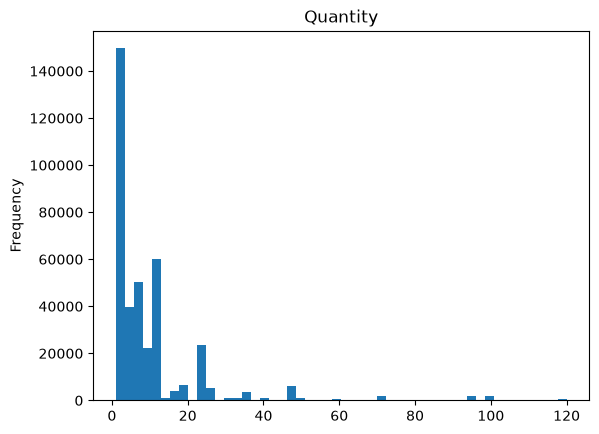

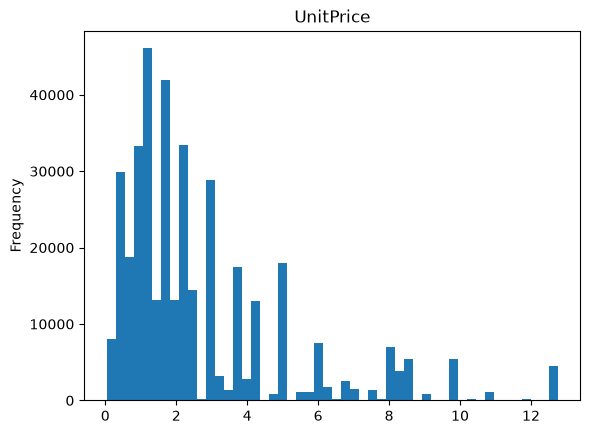

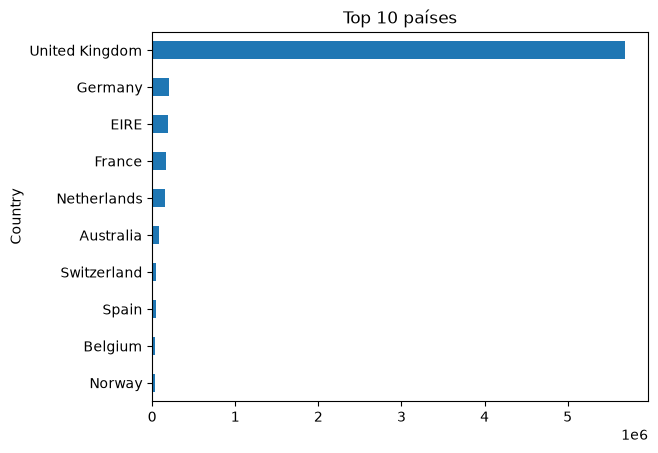

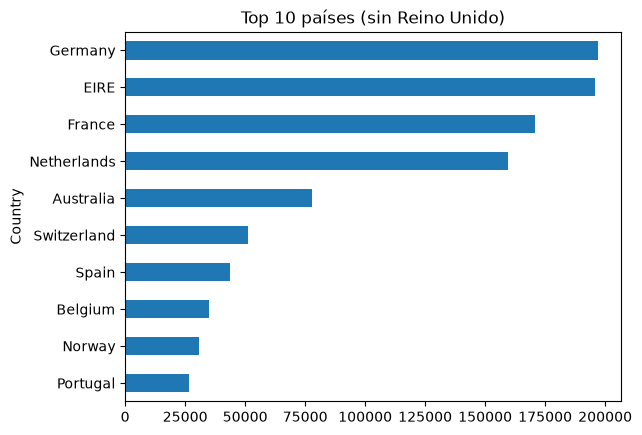

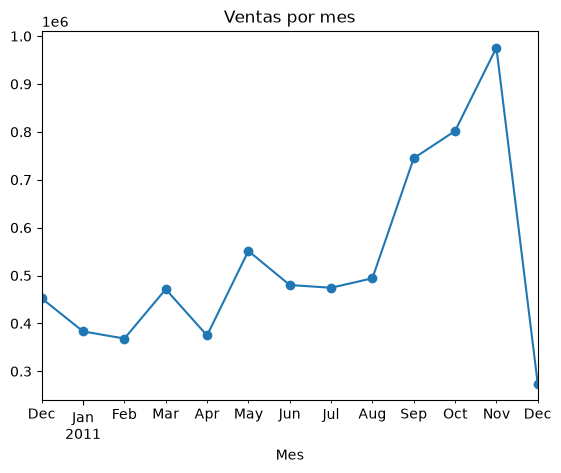

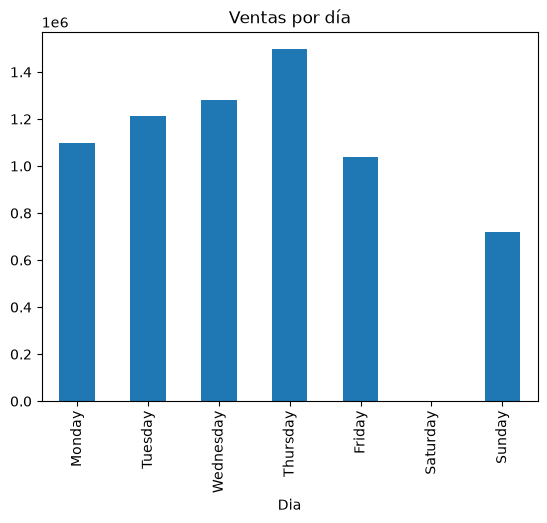

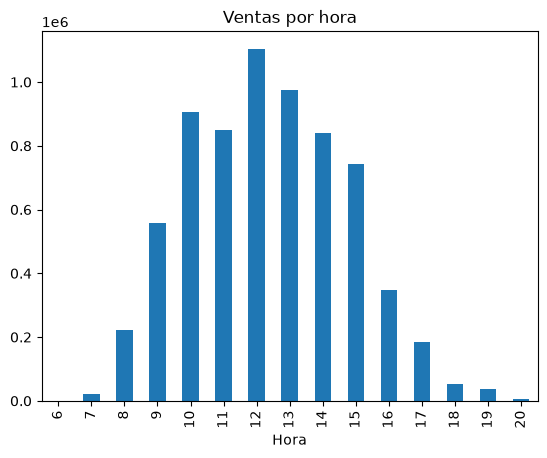

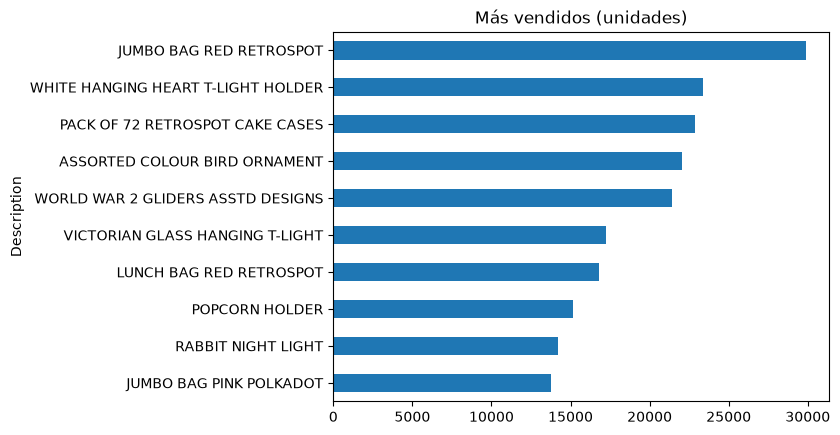

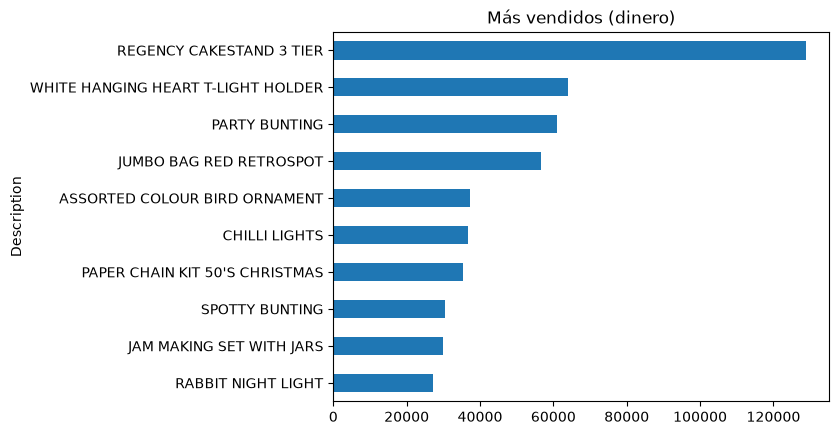


TOP 10 CLIENTES POR VENTAS
CustomerID
14646    154991.10
14911    124091.32
17511     73056.39
14156     67860.24
18102     66370.00
12415     65628.97
15311     56440.96
13089     54827.66
14088     48311.16
14096     47448.70
Name: Total, dtype: float64


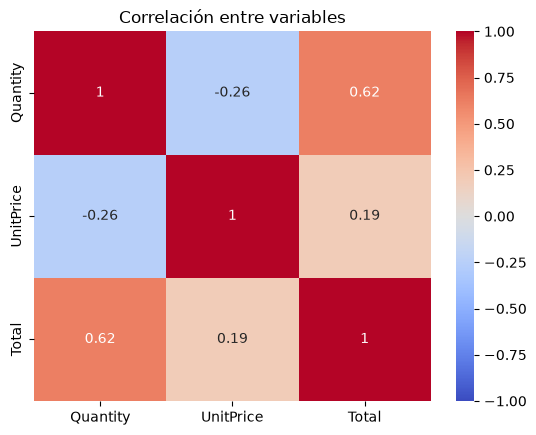

In [34]:
pipeline.eda()

In [9]:
"""pipeline.convertir_tipos(
    columnas_int=["CustomerID"],
    columnas_fecha=["InvoiceDate"]
)

pipeline.filtrar_facturas_canceladas(
    obtener=False
)

pipeline.tratar_nulos(
    columnas=["Description"], # Se poseen suficientes valores para trabajar. 
    metodo="eliminar"        # Ademas, es una cantidad muy pequeña y es la variable objetivo
)

pipeline.eliminar_columnas(["CustomerID"]) # No es necesaria para el analisis
pipeline.analizar()"""

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                   str
dtype: object

Se eliminaron las facturas canceladas.
Se eliminaron los nulos de: Description
Columnas eliminadas: ['CustomerID']
ARCHIVO: online_retail.csv

INFORMACION GENERAL DEL DATASET:
<class 'pandas.DataFrame'>
Index: 531167 entries, 0 to 541908
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    531167 non-null  str           
 1   StockCode    531167 non-null  str           
 2   Description  531167 non-null  str           
 3   Quantity     531167 non-null  int64         
 4   InvoiceDate  531167 non-null  datetime64[us]
 5   UnitPrice    531167 non-null  float64       
 6   Country      531167 non-null  str           
dtypes: datetime64[us](1)